Paso 2: Script de Descarga y Lectura Básica

Descargar los archivos directamente desde los servidores de PhysioNet a tu entorno local sin necesidad de navegación manual:

In [2]:
#!pip install wfdb numpy matplotlib
import matplotlib.pyplot as plt
import wfdb

# 1. Definir el registro y el canal deseado
RECORD_NAME = "100"  # Registro de ejemplo
CHANNEL = 0  # Primer canal (por lo general Derivación MLII)

# 2. Descargar e importar directamente en memoria
# (WFDB descarga los archivos .dat y .hea en la carpeta actual)
record = wfdb.rdrecord(RECORD_NAME, pn_dir="mitdb")

# 3. Extraer la señal, frecuencia de muestreo y unidades
signal = record.p_signal[:, CHANNEL]  # Señal en mV
fs = record.fs  # Frecuencia de muestreo (360 Hz para MIT-BIH)
units = record.units[CHANNEL]

print(f"Registro {RECORD_NAME} cargado con éxito.")
print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Total de muestras: {len(signal)} ({len(signal)/fs:.1f} segundos)")

Registro 100 cargado con éxito.
Frecuencia de muestreo (fs): 360 Hz
Total de muestras: 650000 (1805.6 segundos)


Paso 3: Extraer un Fragmento Temporal (Segmentación)

Para trabajar con ventanas temporales manejables (por ejemplo, los primeros 10 segundos de la señal):

In [3]:
# Definir ventana de tiempo en segundos
t_inicio = 0
t_fin = 10

# Convertir segundos a número de muestras
n_inicio = int(t_inicio * fs)
n_fin = int(t_fin * fs)

# Cortar la señal y generar vector de tiempo
ecg_segmento = signal[n_inicio:n_fin]
tiempo = [i / fs for i in range(len(ecg_segmento))]

Paso 4: Visualizar la Señal Descargada

Comprueba que la señal se haya descargado correctamente graficando el segmento extraído:

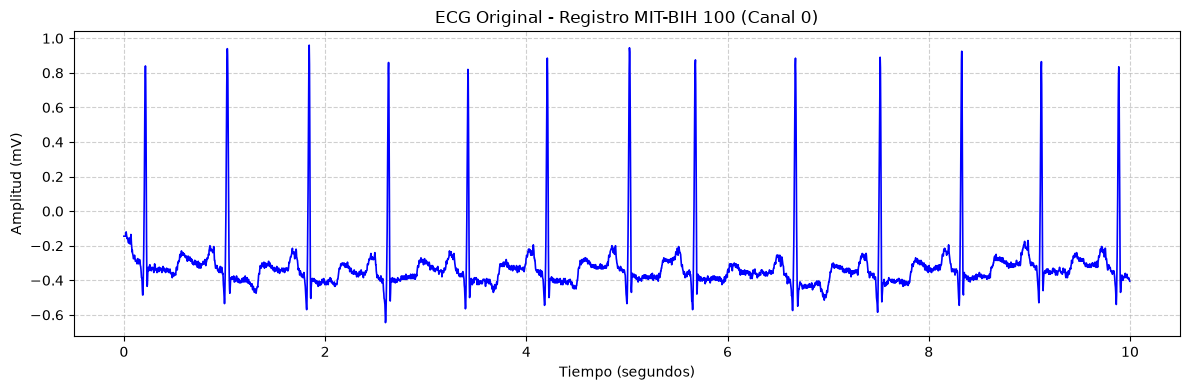

In [4]:
plt.figure(figsize=(12, 4))
plt.plot(tiempo, ecg_segmento, color="b", linewidth=1.2)
plt.title(f"ECG Original - Registro MIT-BIH {RECORD_NAME} (Canal {CHANNEL})")
plt.xlabel("Tiempo (segundos)")
plt.ylabel(f"Amplitud ({units})")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np

# Definición de las 8 direcciones (Conectividad 8) en sentido horario:
# 0: Derecha, 1: Abajo-Derecha, 2: Abajo, 3: Abajo-Izquierda,
# 4: Izquierda, 5: Arriba-Izquierda, 6: Arriba, 7: Arriba-Derecha
OFFSETS = [
    (0, 1),   # 0: Derecha
    (1, 1),   # 1: Abajo-Derecha
    (1, 0),   # 2: Abajo -> corrección (1, 0)
    (1, -1),  # 3: Abajo-Izquierda
    (0, -1),  # 4: Izquierda
    (-1, -1), # 5: Arriba-Izquierda
    (-1, 0),  # 6: Arriba
    (-1, 1)   # 7: Arriba-Derecha
]

def trace_boundary(grid: np.ndarray, start_pt: tuple):
    """
    Rastrea el contorno de un objeto binario comenzando en start_pt.
    Devuelve la lista de puntos del contorno y el Código de Cadena (Chain Code).
    """
    h, w = grid.shape
    r_start, c_start = start_pt
    
    contour_points = [start_pt]
    visited = grid
    chain_code = []
    
    current_r, current_c = r_start, c_start
    # Dirección inicial desde la que empezamos a buscar (4 = izquierda)
    dir_to_search = 4
    
    while True:
        found_next = False
        
        # Probar las 8 direcciones en sentido horario partiendo del último sentido
        for i in range(8):
            check_dir = (dir_to_search + i) % 8
            dr, dc = OFFSETS[check_dir]
            next_r, next_c = current_r + dr, current_c + dc
            
            # Verificar que no nos salimos de la matriz y que sea un píxel activo (1 / True)
            if 0 <= next_r < h and 0 <= next_c < w and grid[next_r, next_c]:
                # ¡Siguiente píxel de borde encontrado!
                contour_points.append((next_r, next_c))
                chain_code.append(check_dir)
                
                # Actualizar posición actual
                current_r, current_c = next_r, next_c
                
                # Ajustar la dirección de búsqueda para el siguiente paso:
                # Se retrocede 2 posiciones para no saltarse esquinas pegadas
                dir_to_search = (check_dir + 5) % 8 
                found_next = True
                break
                
        # Si volvimos al punto inicial (o no hay más vecinos), hemos cerrado el contorno
        if (current_r, current_c) == (r_start, c_start) or not found_next:
            break
            
    return contour_points, chain_code


# --- DEMOSTRACIÓN ---

# Crear una matriz 7x7 con una forma (un cuadrado 3x3)
grid = np.zeros((7, 7), dtype=int)
grid[1:4, 1:4] = 1

grid[5:7, 5:7] = 1

print("Matriz de entrada (1 = Objeto, 0 = Fondo):")
print(grid)

# Píxel inicial de borde (esquina superior izquierda del objeto)
start_pixel = (2, 2)

points, code = trace_boundary(grid, start_pixel)

print("\n--- RESULTADO DEL RASTREO ---")
print(f"Puntos del contorno recorridos ({len(points)} píxeles):")
print(points)

print(f"\nCódigo de Cadena (Chain Code - Direcciones):")
print(code)

Matriz de entrada (1 = Objeto, 0 = Fondo):
[[0 0 0 0 0 0 0]
 [0 1 1 1 0 0 0]
 [0 1 1 1 0 0 0]
 [0 1 1 1 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 1 1]
 [0 0 0 0 0 1 1]]

--- RESULTADO DEL RASTREO ---
Puntos del contorno recorridos (4 píxeles):
[(2, 2), (2, 1), (3, 2), (2, 2)]

Código de Cadena (Chain Code - Direcciones):
[4, 1, 6]
